In [222]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd


# Preprocessing

In [223]:
data = pd.read_csv("csvs/jakarta_house.csv")

In the data below, we can see some obvious outliers such as:
- Minimum Price being 1.85 million IDR
- Maximum Bed rooms being 63
- Maximum Car Port as 31
- Land Area of 17714 m^2
- Building Area of 15331 m^2
So we're going to filter the data

In [224]:
data.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,9997.000000,9995.000000
mean,5000.50000,1.004029e+10,4.253500,3.521300,1.578900,296.610183,319.962481
std,2886.89568,2.004519e+10,3.176609,2.900136,1.743467,502.921686,357.676034
min,1.00000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2500.75000,2.500000e+09,3.000000,2.000000,1.000000,100.000000,139.000000
50%,5000.50000,4.500000e+09,4.000000,3.000000,1.000000,177.000000,230.000000
75%,7500.25000,9.800000e+09,5.000000,4.000000,2.000000,335.000000,400.000000
max,10000.00000,9.000000e+11,63.000000,63.000000,31.000000,17714.000000,15331.000000


## Visual Distribution of the data
 We can see that most of the data are heavily right skewed especially price, land_area and building_area. <br>
 To make it more gaussian, we can apply log_transform later on in the pipeline. <br>

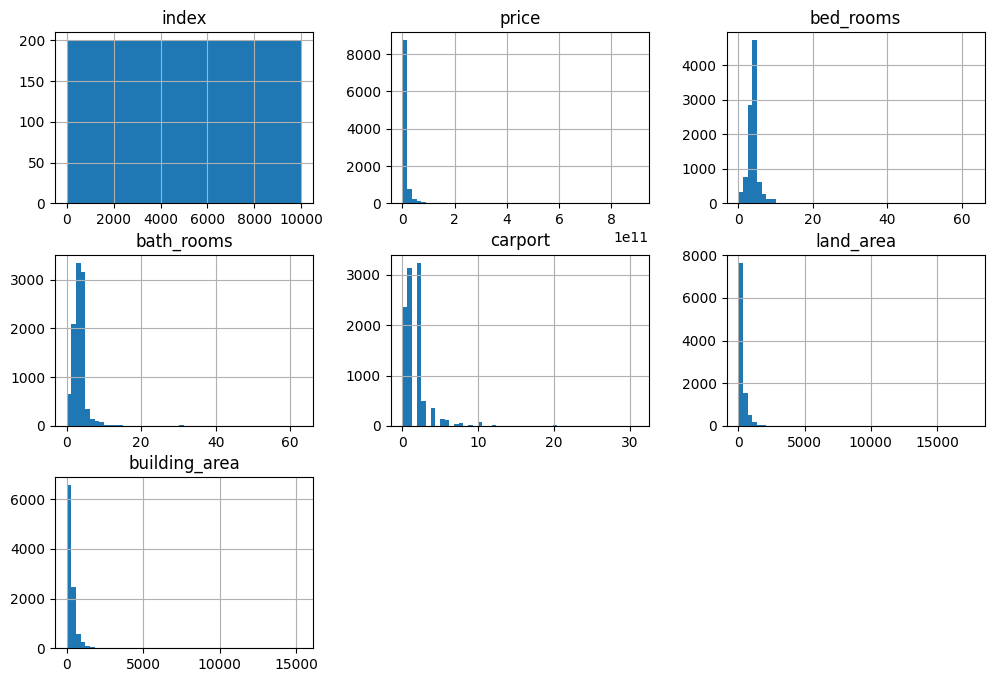

In [225]:
data.hist(bins = 50, figsize=(12,8))
plt.title("Data Distribution Before Transformation")
plt.savefig("images/Data Distribution Before Transformation.png")
plt.show()


In [226]:
data = data[(data.bed_rooms <= 10) & (data.carport <= 10)  & (data.bath_rooms <= 10) & (data.building_area <= 1000) & (data.land_area <= 1000) & (data.price <= 1e+11) & (data.price >= 1e+08)]

In [227]:
data.info()

<class 'pandas.DataFrame'>
Index: 9296 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          9296 non-null   int64  
 1   price          9296 non-null   int64  
 2   district       9296 non-null   str    
 3   city           9296 non-null   str    
 4   bed_rooms      9296 non-null   int64  
 5   bath_rooms     9296 non-null   int64  
 6   carport        9296 non-null   int64  
 7   land_area      9296 non-null   float64
 8   building_area  9296 non-null   float64
dtypes: float64(2), int64(5), str(2)
memory usage: 946.3 KB


In [228]:
data.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


In [229]:
data['district'].value_counts()

district
Kelapa Gading         417
Pondok Indah          339
Tebet                 326
Sunter                317
Pantai Indah Kapuk    316
                     ... 
Terogong                1
Taman Cosmos            1
Rawa Badak              1
Kamal                   1
Gelong Baru             1
Name: count, Length: 249, dtype: int64

## Categorical Data with High Cardinality Preprocessing
As we can see above, the district feature has many types of values. <br>
So, we can't just apply One-Hot-Encoding directly as it will cause the dataset to expand massively and consumes more memory. <br>
To fix that, I decided to group the district with value count less than 100 into one group called Others <br>


In [230]:
counts = (data['district'].value_counts()) 
counts

district
Kelapa Gading         417
Pondok Indah          339
Tebet                 326
Sunter                317
Pantai Indah Kapuk    316
                     ... 
Terogong                1
Taman Cosmos            1
Rawa Badak              1
Kamal                   1
Gelong Baru             1
Name: count, Length: 249, dtype: int64

In [231]:
important = counts[counts >= 100]
important

district
Kelapa Gading           417
Pondok Indah            339
Tebet                   326
Sunter                  317
Pantai Indah Kapuk      316
Kebayoran Baru          293
Citra Garden            255
Jagakarsa               227
Lebak Bulus             206
Cilandak                202
Jakarta Garden City     195
Rawamangun              186
Duri Kepa               178
Jelambar                175
Green Lake City         167
Kemang                  161
Tanjung Duren           152
Cakung                  150
Cibubur                 146
Meruya                  143
Cipete                  142
Pondok Kelapa           131
Pantai Indah Kapuk 2    130
Menteng                 120
Muara Karang            119
Duren Sawit             118
Cempaka Putih           113
Permata Buana           111
Bintaro                 108
Puri Indah              103
Name: count, dtype: int64

In [232]:
transformed_district = data['district'].where(data['district'].isin(important.index),'Others')
transformed_district.value_counts()
        

district
Others                  3550
Kelapa Gading            417
Pondok Indah             339
Tebet                    326
Sunter                   317
Pantai Indah Kapuk       316
Kebayoran Baru           293
Citra Garden             255
Jagakarsa                227
Lebak Bulus              206
Cilandak                 202
Jakarta Garden City      195
Rawamangun               186
Duri Kepa                178
Jelambar                 175
Green Lake City          167
Kemang                   161
Tanjung Duren            152
Cakung                   150
Cibubur                  146
Meruya                   143
Cipete                   142
Pondok Kelapa            131
Pantai Indah Kapuk 2     130
Menteng                  120
Muara Karang             119
Duren Sawit              118
Cempaka Putih            113
Permata Buana            111
Bintaro                  108
Puri Indah               103
Name: count, dtype: int64

In [233]:
data['district'] = transformed_district
data['district'].value_counts()

district
Others                  3550
Kelapa Gading            417
Pondok Indah             339
Tebet                    326
Sunter                   317
Pantai Indah Kapuk       316
Kebayoran Baru           293
Citra Garden             255
Jagakarsa                227
Lebak Bulus              206
Cilandak                 202
Jakarta Garden City      195
Rawamangun               186
Duri Kepa                178
Jelambar                 175
Green Lake City          167
Kemang                   161
Tanjung Duren            152
Cakung                   150
Cibubur                  146
Meruya                   143
Cipete                   142
Pondok Kelapa            131
Pantai Indah Kapuk 2     130
Menteng                  120
Muara Karang             119
Duren Sawit              118
Cempaka Putih            113
Permata Buana            111
Bintaro                  108
Puri Indah               103
Name: count, dtype: int64

In [234]:
transformed_district_index = pd.Series(important.index)
transformed_district_index.to_csv('csvs/Important_Districts.csv')

In [235]:
data.info()

<class 'pandas.DataFrame'>
Index: 9296 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          9296 non-null   int64  
 1   price          9296 non-null   int64  
 2   district       9296 non-null   str    
 3   city           9296 non-null   str    
 4   bed_rooms      9296 non-null   int64  
 5   bath_rooms     9296 non-null   int64  
 6   carport        9296 non-null   int64  
 7   land_area      9296 non-null   float64
 8   building_area  9296 non-null   float64
dtypes: float64(2), int64(5), str(2)
memory usage: 932.5 KB


In [236]:
data['city'].value_counts() #city only has 4 values so it can be one hot encoded directly

city
Jakarta Selatan    2965
Jakarta Barat      2546
Jakarta Timur      1657
Jakarta Utara      1624
Jakarta Pusat       504
Name: count, dtype: int64

In [237]:
data.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,9296.000000,9.296000e+03,9296.000000,9296.000000,9296.000000,9296.000000,9296.000000
mean,5010.918997,7.420070e+09,3.881239,3.208799,1.427388,232.330572,269.037543
std,2884.496675,9.517769e+09,1.453859,1.338298,1.303242,194.357477,190.893943
min,1.000000,1.160000e+08,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2507.750000,2.400000e+09,3.000000,2.000000,1.000000,98.000000,130.000000
50%,5030.500000,4.000000e+09,4.000000,3.000000,1.000000,160.000000,208.000000
75%,7504.250000,8.500000e+09,5.000000,4.000000,2.000000,300.000000,350.000000
max,10000.000000,1.000000e+11,10.000000,10.000000,10.000000,1000.000000,1000.000000


In [238]:
X = data.drop(columns=['price'])
y = data['price']

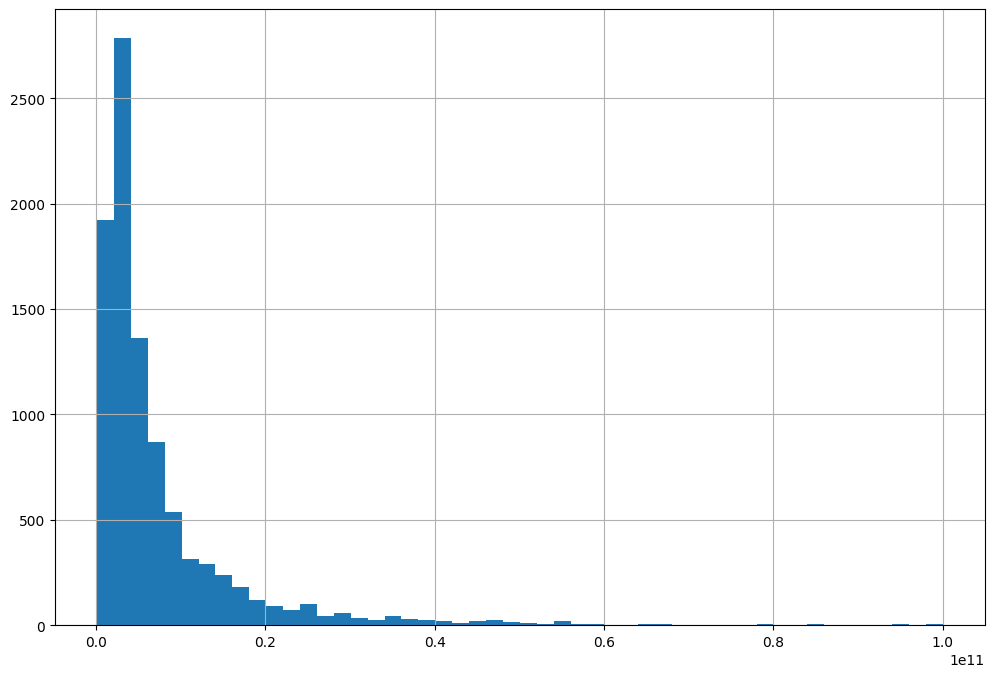

In [239]:
y.hist(figsize=(12,8),bins=50)
plt.show()

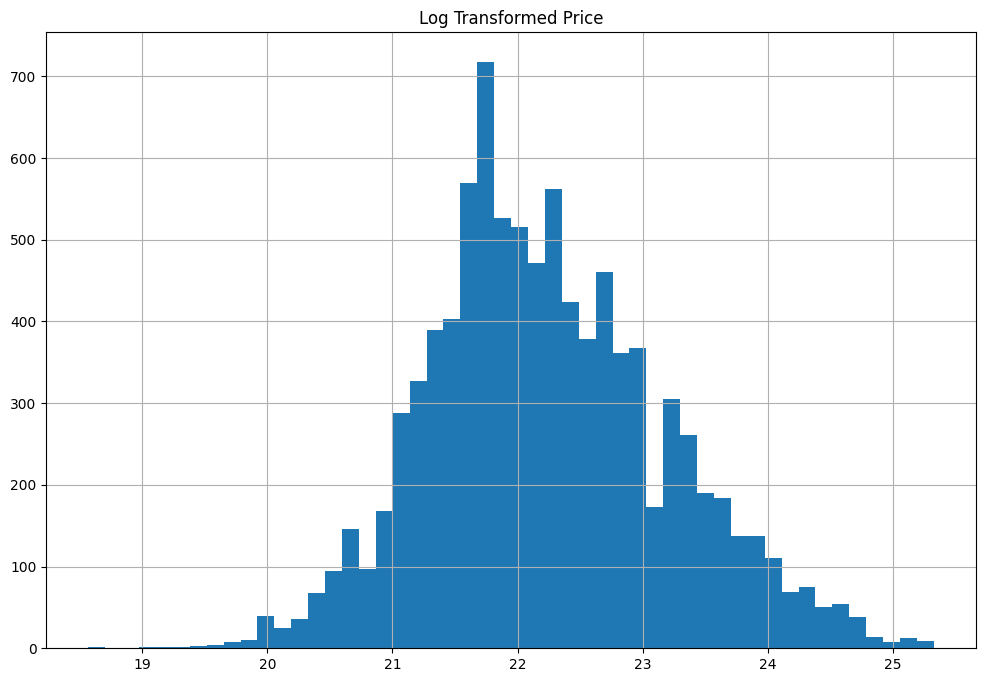

In [240]:
np.log1p(y).hist(figsize = (12,8), bins = 50)
plt.title("Log Transformed Price")
plt.savefig("images/Log Transformed Price.png")
plt.show()


In [241]:
X.info()

<class 'pandas.DataFrame'>
Index: 9296 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          9296 non-null   int64  
 1   district       9296 non-null   str    
 2   city           9296 non-null   str    
 3   bed_rooms      9296 non-null   int64  
 4   bath_rooms     9296 non-null   int64  
 5   carport        9296 non-null   int64  
 6   land_area      9296 non-null   float64
 7   building_area  9296 non-null   float64
dtypes: float64(2), int64(4), str(2)
memory usage: 859.9 KB


In [242]:
y.info()

<class 'pandas.Series'>
Index: 9296 entries, 0 to 9999
Series name: price
Non-Null Count  Dtype
--------------  -----
9296 non-null   int64
dtypes: int64(1)
memory usage: 145.2 KB


In [243]:
y = np.log1p(y)

# Data Splitting

In [244]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.3,stratify=X['district'],random_state=67
    
) #data is stratified based on the district

In [245]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 6507 entries, 7412 to 4021
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          6507 non-null   int64  
 1   district       6507 non-null   str    
 2   city           6507 non-null   str    
 3   bed_rooms      6507 non-null   int64  
 4   bath_rooms     6507 non-null   int64  
 5   carport        6507 non-null   int64  
 6   land_area      6507 non-null   float64
 7   building_area  6507 non-null   float64
dtypes: float64(2), int64(4), str(2)
memory usage: 602.7 KB


In [246]:
X_train.describe()

,index,bed_rooms,bath_rooms,carport,land_area,building_area
count,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000
mean,5010.350546,3.868910,3.202244,1.440756,232.624558,269.739050
std,2887.487694,1.459315,1.345019,1.322202,195.070708,192.933369
min,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2474.500000,3.000000,2.000000,1.000000,98.000000,130.000000
50%,5045.000000,4.000000,3.000000,1.000000,160.000000,205.000000
75%,7496.500000,5.000000,4.000000,2.000000,300.000000,350.000000
max,10000.000000,10.000000,10.000000,10.000000,1000.000000,1000.000000


In [247]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 2789 entries, 3100 to 3943
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          2789 non-null   int64  
 1   district       2789 non-null   str    
 2   city           2789 non-null   str    
 3   bed_rooms      2789 non-null   int64  
 4   bath_rooms     2789 non-null   int64  
 5   carport        2789 non-null   int64  
 6   land_area      2789 non-null   float64
 7   building_area  2789 non-null   float64
dtypes: float64(2), int64(4), str(2)
memory usage: 258.4 KB


# Scikit-Learn Pipeline 

In [248]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import PolynomialFeatures, FunctionTransformer
cat_features = ['district','city']
num_features = ['bed_rooms','bath_rooms','carport']
num_log_features = ['land_area','building_area']
num_pipeline = Pipeline([
    ("impute",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
    
])

num_log_pipeline = Pipeline([
      ("impute",SimpleImputer(strategy="median")),
      ("log",FunctionTransformer(func=np.log1p,feature_names_out="one-to-one")),
      ("scaler",StandardScaler())
])


quadratic_pipeline = Pipeline([
    ("impute",SimpleImputer(strategy="median")),
    ("quadratic", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler",StandardScaler())

])

quadratic_log_pipeline = Pipeline([
      ("impute",SimpleImputer(strategy="median")),
      ("log",FunctionTransformer(func=np.log1p,feature_names_out="one-to-one")),
      ("quadratic", PolynomialFeatures(degree=2, include_bias=False)),
      ("scaler",StandardScaler())
])

cat_pipeline = Pipeline([
    ("encoder",OneHotEncoder(drop='first',sparse_output=False,handle_unknown='ignore'))
])

preprocessing = ColumnTransformer([
    ("num",num_pipeline,num_features),
    ("log",num_log_pipeline,num_log_features),
    ("cat",cat_pipeline,cat_features)
])



preprocessing_quad = ColumnTransformer([
    ("quad",quadratic_pipeline,num_features),
    ("log",quadratic_log_pipeline,num_log_features),
    ("cat",cat_pipeline,cat_features)
])

In [249]:
X_train_transformed = preprocessing.fit_transform(X_train)

In [250]:
X_train_transformed = pd.DataFrame(X_train_transformed,columns= preprocessing.get_feature_names_out(),index = X_train.index)

In [251]:
X_train_transformed.info()

<class 'pandas.DataFrame'>
Index: 6507 entries, 7412 to 4021
Data columns (total 39 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   num__bed_rooms                      6507 non-null   float64
 1   num__bath_rooms                     6507 non-null   float64
 2   num__carport                        6507 non-null   float64
 3   log__land_area                      6507 non-null   float64
 4   log__building_area                  6507 non-null   float64
 5   cat__district_Cakung                6507 non-null   float64
 6   cat__district_Cempaka Putih         6507 non-null   float64
 7   cat__district_Cibubur               6507 non-null   float64
 8   cat__district_Cilandak              6507 non-null   float64
 9   cat__district_Cipete                6507 non-null   float64
 10  cat__district_Citra Garden          6507 non-null   float64
 11  cat__district_Duren Sawit           6507 non-null   floa

In [252]:
X_train_transformed.describe()

,num__bed_rooms,num__bath_rooms,num__carport,log__land_area,log__building_area,cat__district_Cakung,cat__district_Cempaka Putih,cat__district_Cibubur,cat__district_Cilandak,cat__district_Cipete,...,cat__district_Pondok Kelapa,cat__district_Puri Indah,cat__district_Rawamangun,cat__district_Sunter,cat__district_Tanjung Duren,cat__district_Tebet,cat__city_Jakarta Pusat,cat__city_Jakarta Selatan,cat__city_Jakarta Timur,cat__city_Jakarta Utara
count,6.507000e+03,6.507000e+03,6.507000e+03,6.507000e+03,6.507000e+03,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000,...,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000,6507.000000
mean,-1.190244e-16,1.135645e-16,1.310360e-17,-3.477914e-16,-7.534570e-17,0.016136,0.012141,0.015675,0.021669,0.015214,...,0.014139,0.011065,0.019978,0.034117,0.016290,0.035039,0.053174,0.316428,0.179499,0.176272
std,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,1.000077e+00,0.126010,0.109523,0.124226,0.145611,0.122414,...,0.118071,0.104615,0.139937,0.181544,0.126599,0.183893,0.224397,0.465118,0.383799,0.381080
min,-2.651386e+00,-2.381000e+00,-1.089748e+00,-5.807806e+00,-6.060498e+00,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-5.954692e-01,-8.939177e-01,-3.333756e-01,-7.311595e-01,-6.182458e-01,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,8.983644e-02,-1.503765e-01,-3.333756e-01,-9.848084e-02,-2.915854e-02,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7.751421e-01,5.931646e-01,4.229965e-01,7.155915e-01,6.643365e-01,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,4.201670e+00,5.054411e+00,6.473973e+00,2.278987e+00,2.028096e+00,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [253]:
X_train_transformed.head()

,num__bed_rooms,num__bath_rooms,num__carport,log__land_area,log__building_area,cat__district_Cakung,cat__district_Cempaka Putih,cat__district_Cibubur,cat__district_Cilandak,cat__district_Cipete,...,cat__district_Pondok Kelapa,cat__district_Puri Indah,cat__district_Rawamangun,cat__district_Sunter,cat__district_Tanjung Duren,cat__district_Tebet,cat__city_Jakarta Pusat,cat__city_Jakarta Selatan,cat__city_Jakarta Timur,cat__city_Jakarta Utara
7412,0.089836,-0.150377,0.422996,0.749719,0.464352,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8785,-0.595469,-0.150377,-0.333376,-1.594136,-0.956693,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1818,-0.595469,-0.150377,0.422996,-0.642273,-0.433349,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1427,0.089836,-0.150377,0.422996,0.564510,0.611368,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3110,0.775142,1.336706,0.422996,1.241679,1.364206,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


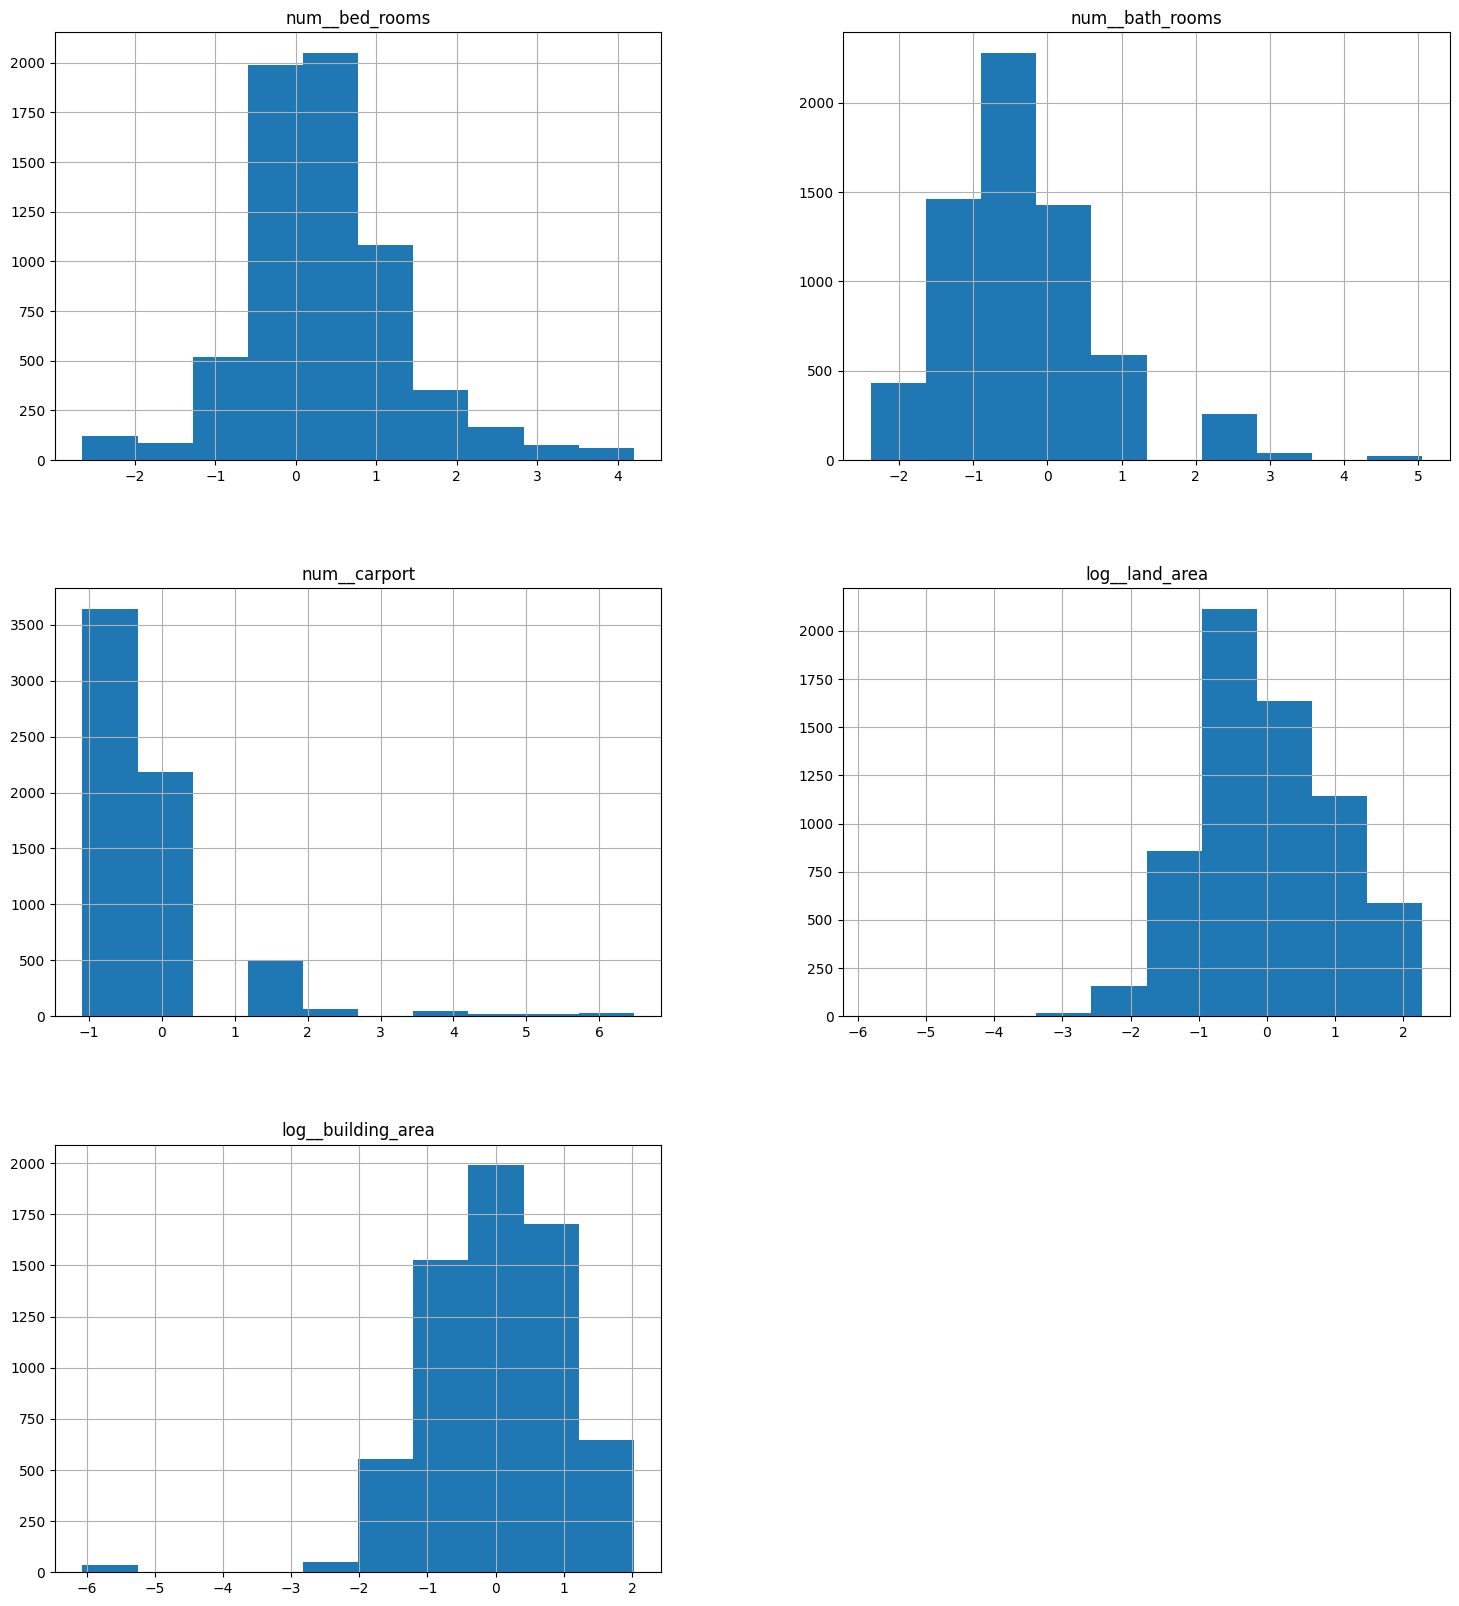

In [254]:
X_train_transformed.iloc[:, :5].hist(figsize=(18,20))
plt.title("Features Distribution After Transformation")
plt.savefig("images/Features Distribution After Transformation.png")
plt.show()


In [255]:
X_test_transformed = preprocessing.fit_transform(X_test)

In [256]:
X_test_transformed = pd.DataFrame(X_test_transformed,columns=preprocessing.get_feature_names_out(),index=X_test.index)

# Model Fitting

In [257]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

linreg_model = Pipeline([
    ("preprocess",preprocessing),
    ("model",LinearRegression())
])
cv_rmses = -cross_val_score(linreg_model, X_train, y_train,scoring="neg_root_mean_squared_error",cv = 10)
cv_rmses = pd.Series(cv_rmses)
linear_cvs_desc = cv_rmses.describe()

In [258]:
def adjusted_r2(r2,n,p):
    return 1- ((1-r2)* (n-1)) / (n-p)
#scikit-learn doesn't have adjusted r2 so I decided to write it by myself


## Adjusted R2
Adjusted R2 is used because the more features you have, plain R2 will inflate the score.

In [259]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_squared_error, r2_score


linreg_model.fit(X_train,y_train)
prediction = linreg_model.predict(X_test)
lin_rmse = root_mean_squared_error(y_test,prediction)
lin_mse = mean_squared_error(y_test,prediction)
lin_mae = mean_absolute_error(y_test,prediction)
lin_r2 = r2_score(y_test,prediction)
lin_adjr2 = adjusted_r2(lin_r2, X_train.shape[0], X_train.shape[1])

print(f"RMSE: {lin_rmse}")
print(f"MSE: {lin_mse}")
print(f"MAE: {lin_mae}")
print(f"R2: {lin_r2}")
print(f"Adjusted R2: {lin_adjr2}")
print(f"Coefficients: {linreg_model["model"].coef_}")
print(f"Intercept: {linreg_model["model"].intercept_}")

linreg_results = pd.Series([lin_rmse, lin_mse,lin_mae, lin_r2, lin_adjr2], index=["RMSE","MSE","MAE","R2","AdjR2"])


RMSE: 0.37305891055119755
MSE: 0.1391729507416464
MAE: 0.26945470586140713
R2: 0.8429794591374102
Adjusted R2: 0.8428103340741638
Coefficients: [-0.03815309  0.09311338  0.03037502  0.55721439  0.18756688  0.33056402
  0.2235427   0.07298614  0.2953154   0.33781999  0.21676804  0.30515226
  0.31954885  0.34572175 -0.10103332  0.38007796  0.31835719  1.01417737
  0.27784486  0.5053524   0.20429194  1.1625086   0.11716251  0.35173117
  0.27712845  0.67540599  0.41810686  0.70658731  0.80745025  0.21110476
  0.53771134  0.59423708  0.35075698  0.44227309  0.33497444  0.15901201
  0.12424897 -0.29341421  0.16528029]
Intercept: 21.855918348092075


In [260]:
coefs = pd.Series(linreg_model["model"].coef_, index = preprocessing.get_feature_names_out()).sort_values(ascending=False)
coefs[:5].to_csv("csvs/Five Highest Coefficients Lin Reg.csv")
coefs.to_csv("csvs/LinReg Coefs.csv")
coefs[:5]

cat__district_Menteng               1.162509
cat__district_Kebayoran Baru        1.014177
cat__district_Pondok Indah          0.807450
cat__district_Permata Buana         0.706587
cat__district_Pantai Indah Kapuk    0.675406
dtype: float64

## Linear Regression Residual Plot
We can see that the residual plot is good because there's no funnel shape and obvious pattern. <br>
There's one outlier at the corner though<br>

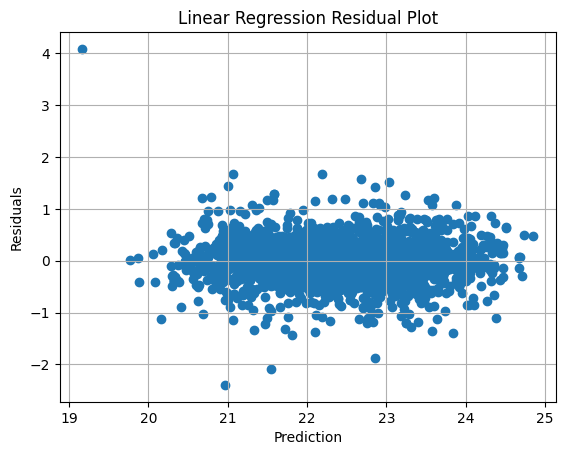

In [261]:
plt.scatter(prediction, (y_test - prediction))
plt.title("Linear Regression Residual Plot")
plt.grid(True)
plt.xlabel("Prediction")
plt.ylabel("Residuals")
plt.savefig("images/Linear Regression Residual Plot.png")
plt.show()


## Statsmodels Summary for Linear Regression
The Overall F-test and p-value shows the model has a significant relationship. <br>
The Cibubur district has high p-value from the t-test which indicates weak relationship although t-test can incorrectly reject null hypothesis as number of predictors increase.

In [262]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF
X_train_intercept = sm.add_constant(X_train_transformed)
sm_linreg = sm.OLS(y_train,X_train_intercept).fit()
sm_linreg.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.859
Model:                            OLS   Adj. R-squared:                  0.858
Method:                 Least Squares   F-statistic:                     1013.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:21:01   Log-Likelihood:                -2588.1
No. Observations:                6507   AIC:                             5256.
Df Residuals:                    6467   BIC:                             5527.
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
const                                 21.8559      0.045    480.771      0.000      21.767      21.945
num__bed_rooms                        -0.0382      0.007     -5.827      0.000      -0.051      -0.025
num__bath_rooms                        0.0931      0.007     13.962      0.000       0.080       0.106
num__carport                           0.0304      0.005      6.147      0.000       0.021       0.040
log__land_area                         0.5572      0.007     77.829      0.000       0.543       0.571
log__building_area                     0.1876      0.007     26.086      0.000       0.173       0.202
cat__district_Cakung                   0.3306      0.058      5.656      0.000       0.216       0.445
cat__district_Cempaka Putih            0.2235      0.065      3.415      0.001       0.095       0.352
cat__district_Cibubur                  0.0730      0.059      1.242      0.214      -0.042       0.188
cat__district_Cilandak                 0.2953      0.051      5.737      0.000       0.194       0.396
cat__district_Cipete                   0.3378      0.055      6.120      0.000       0.230       0.446
cat__district_Citra Garden             0.2168      0.053      4.096      0.000       0.113       0.321
cat__district_Duren Sawit              0.3052      0.061      4.984      0.000       0.185       0.425
cat__district_Duri Kepa                0.3195      0.056      5.719      0.000       0.210       0.429
cat__district_Green Lake City          0.3457      0.056      6.122      0.000       0.235       0.456
cat__district_Jagakarsa               -0.1010      0.051     -1.994      0.046      -0.200      -0.002
cat__district_Jakarta Garden City      0.3801      0.056      6.798      0.000       0.270       0.490
cat__district_Jelambar                 0.3184      0.056      5.683      0.000       0.209       0.428
cat__district_Kebayoran Baru           1.0142      0.049     20.846      0.000       0.919       1.110
cat__district_Kelapa Gading            0.2778      0.054      5.144      0.000       0.172       0.384
cat__district_Kemang                   0.5054      0.054      9.389      0.000       0.400       0.611
cat__district_Lebak Bulus              0.2043      0.051      3.986      0.000       0.104       0.305
cat__district_Menteng                  1.1625      0.065     17.812      0.000       1.035       1.290
cat__district_Meruya                   0.1172      0.058      2.017      0.044       0.003       0.231
cat__district_Muara Karang             0.3517      0.064      5.533      0.000       0.227       0.476
cat__district_Others                   0.2771      0.044      6.329      0.000       0.191       0.363
cat__district_Pantai Indah Kapuk       0.6754      0.055     12.207      0.000       0.567      

In [263]:
vif_linear = [VIF(X_train_intercept,i) for i in range(1,X_train_intercept.shape[1])]
vif_linear = pd.Series(vif_linear,index=X_train_intercept.columns[1:])
vif_linear_sus = vif_linear[vif_linear >= 5]
vif_linear_sus.to_csv("csvs/High VIF Linear Model.csv")

## Suspicious VIF
We can see that the Others feature has high VIF score. <br>
It could be because many districts are put into the same class which causes high colinearity? <br>
High VIF might cause the inference to be unreliable although the prediction should be fine. <br>

In [264]:
vif_linear_sus

cat__district_Kelapa Gading          6.234082
cat__district_Others                22.566556
cat__district_Pantai Indah Kapuk     5.007673
cat__district_Sunter                 5.042845
cat__city_Jakarta Utara              5.085777
dtype: float64

In [296]:
X_train_transformed.corr()['cat__district_Others'].sort_values()

cat__district_Kelapa Gading          -0.170378
cat__city_Jakarta Utara              -0.166050
cat__district_Pondok Indah           -0.152821
cat__district_Tebet                  -0.149784
cat__district_Sunter                 -0.147729
cat__district_Pantai Indah Kapuk     -0.147384
cat__district_Kebayoran Baru         -0.141769
cat__district_Citra Garden           -0.131821
cat__district_Jagakarsa              -0.124401
cat__district_Lebak Bulus            -0.118248
cat__district_Cilandak               -0.116982
cat__district_Jakarta Garden City    -0.115274
cat__district_Rawamangun             -0.112229
cat__district_Duri Kepa              -0.110007
cat__district_Jelambar               -0.109106
cat__district_Green Lake City        -0.106362
cat__district_Kemang                 -0.104495
cat__district_Tanjung Duren          -0.101151
cat__district_Cakung                 -0.100665
cat__district_Cibubur                -0.099193
cat__district_Meruya                 -0.098201
cat__district

In [265]:
X_train_transformed_quad = preprocessing_quad.fit_transform(X_train)
X_test_transformed_quad = preprocessing_quad.fit_transform(X_test)

In [266]:
X_train_transformed_quad = pd.DataFrame(X_train_transformed_quad,columns=preprocessing_quad.get_feature_names_out(),index=X_train.index)
X_test_transformed_quad = pd.DataFrame(X_test_transformed_quad,columns=preprocessing_quad.get_feature_names_out(),index=X_test.index)


In [267]:
X_train_transformed_quad.info()

<class 'pandas.DataFrame'>
Index: 6507 entries, 7412 to 4021
Data columns (total 48 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   quad__bed_rooms                     6507 non-null   float64
 1   quad__bath_rooms                    6507 non-null   float64
 2   quad__carport                       6507 non-null   float64
 3   quad__bed_rooms^2                   6507 non-null   float64
 4   quad__bed_rooms bath_rooms          6507 non-null   float64
 5   quad__bed_rooms carport             6507 non-null   float64
 6   quad__bath_rooms^2                  6507 non-null   float64
 7   quad__bath_rooms carport            6507 non-null   float64
 8   quad__carport^2                     6507 non-null   float64
 9   log__land_area                      6507 non-null   float64
 10  log__building_area                  6507 non-null   float64
 11  log__land_area^2                    6507 non-null   floa

In [268]:
quad_reg_model = Pipeline([
    ("preprocessing", preprocessing_quad),
    ("model",LinearRegression())
])
quad_reg_model.fit(X_train,y_train)
quad_reg_cv = -cross_val_score(quad_reg_model, X_train, y_train,scoring="neg_root_mean_squared_error",cv=10)
quad_reg_cv = pd.Series(quad_reg_cv)
quad_reg_cv = quad_reg_cv.describe()


In [269]:
prediction_quad = quad_reg_model.predict(X_test)

quad_reg_rmse = root_mean_squared_error(y_test, prediction_quad)
quad_reg_mse = mean_squared_error(y_test, prediction_quad)
quad_reg_mae = mean_absolute_error(y_test, prediction_quad)
quad_reg_r2 = r2_score(y_test, prediction_quad)
quad_reg_adjr2 = adjusted_r2(quad_reg_r2,X_test_transformed_quad.shape[0],X_test_transformed_quad.shape[1])

print(f"RMSE: {quad_reg_rmse}")
print(f"MSE: {quad_reg_mse}")
print(f"MAE: {quad_reg_mae}")
print(f"R2: {quad_reg_r2}")
print(f"AdjR2: {quad_reg_adjr2}")

RMSE: 0.34700342671982015
MSE: 0.12041137815529761
MAE: 0.2567132950925884
R2: 0.8641470226563439
AdjR2: 0.8618175480357121


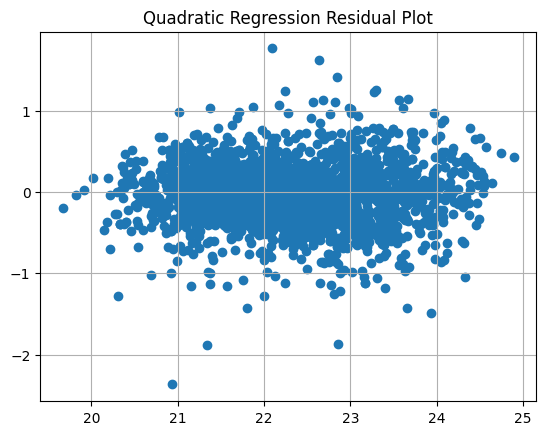

In [270]:
plt.title("Quadratic Regression Residual Plot")
plt.grid(True)
plt.scatter(prediction_quad, (y_test - prediction_quad))
plt.savefig("images/Quadratic Regression Residual Plot.png")
plt.show()

## Quadratic Regression Residual Plot
Even better than the linear regression because there's no outlier sticking out. <br>


In [271]:
price_in_rupiah = pd.Series(np.expm1(prediction_quad))
price_in_rupiah.describe()

count    2.789000e+03
mean     6.848087e+09
std      7.245680e+09
min      3.483266e+08
25%      2.420874e+09
50%      4.153088e+09
75%      8.551913e+09
max      6.465864e+10
dtype: float64

In [272]:
X_train_transformed_quad_with_intercept = sm.add_constant(X_train_transformed_quad)
sm_model_quad = sm.OLS(y_train,X_train_transformed_quad_with_intercept).fit()

In [273]:
sm_model_quad.params

const                                 21.874166
quad__bed_rooms                       -0.035758
quad__bath_rooms                       0.114857
quad__carport                          0.047229
quad__bed_rooms^2                      0.016102
quad__bed_rooms bath_rooms            -0.086763
quad__bed_rooms carport                0.047810
quad__bath_rooms^2                     0.015106
quad__bath_rooms carport              -0.055596
quad__carport^2                       -0.016137
log__land_area                         0.285212
log__building_area                     0.382399
log__land_area^2                       1.052940
log__land_area building_area          -1.581745
log__building_area^2                   0.746714
cat__district_Cakung                   0.364633
cat__district_Cempaka Putih            0.213107
cat__district_Cibubur                  0.100563
cat__district_Cilandak                 0.280364
cat__district_Cipete                   0.324197
cat__district_Citra Garden             0

## Statsmodels Summary for Quadratic Regression
We can see that the overall model is significant based on the F-test and p-value. <br>
The squared term of bath_room and bed_rooms have high p-value which may indicate that they may not be significant. <br>


In [274]:
print(sm_model_quad.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.876
Model:                            OLS   Adj. R-squared:                  0.875
Method:                 Least Squares   F-statistic:                     946.9
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:21:05   Log-Likelihood:                -2187.2
No. Observations:                6507   AIC:                             4472.
Df Residuals:                    6458   BIC:                             4805.
Df Model:                          48                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

In [275]:
X_train_transformed_quad_with_intercept_num_only = X_train_transformed_quad_with_intercept.drop(X_train_transformed_quad_with_intercept.columns[21:],axis =1)
X_train_transformed_quad_with_intercept_cat_only = X_train_transformed_quad_with_intercept.drop(X_train_transformed_quad_with_intercept.columns[:21], axis =1)

In [276]:
print(X_train_transformed_quad_with_intercept_cat_only.columns)

Index(['cat__district_Duren Sawit', 'cat__district_Duri Kepa',
       'cat__district_Green Lake City', 'cat__district_Jagakarsa',
       'cat__district_Jakarta Garden City', 'cat__district_Jelambar',
       'cat__district_Kebayoran Baru', 'cat__district_Kelapa Gading',
       'cat__district_Kemang', 'cat__district_Lebak Bulus',
       'cat__district_Menteng', 'cat__district_Meruya',
       'cat__district_Muara Karang', 'cat__district_Others',
       'cat__district_Pantai Indah Kapuk',
       'cat__district_Pantai Indah Kapuk 2', 'cat__district_Permata Buana',
       'cat__district_Pondok Indah', 'cat__district_Pondok Kelapa',
       'cat__district_Puri Indah', 'cat__district_Rawamangun',
       'cat__district_Sunter', 'cat__district_Tanjung Duren',
       'cat__district_Tebet', 'cat__city_Jakarta Pusat',
       'cat__city_Jakarta Selatan', 'cat__city_Jakarta Timur',
       'cat__city_Jakarta Utara'],
      dtype='str')


In [277]:
X_train_transformed_quad_with_intercept_num_only.info()

<class 'pandas.DataFrame'>
Index: 6507 entries, 7412 to 4021
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   const                         6507 non-null   float64
 1   quad__bed_rooms               6507 non-null   float64
 2   quad__bath_rooms              6507 non-null   float64
 3   quad__carport                 6507 non-null   float64
 4   quad__bed_rooms^2             6507 non-null   float64
 5   quad__bed_rooms bath_rooms    6507 non-null   float64
 6   quad__bed_rooms carport       6507 non-null   float64
 7   quad__bath_rooms^2            6507 non-null   float64
 8   quad__bath_rooms carport      6507 non-null   float64
 9   quad__carport^2               6507 non-null   float64
 10  log__land_area                6507 non-null   float64
 11  log__building_area            6507 non-null   float64
 12  log__land_area^2              6507 non-null   float64
 13  log__land_area b

In [278]:

X_train_transformed_quad_with_intercept_cat_only = sm.add_constant(X_train_transformed_quad_with_intercept_cat_only)
X_train_transformed_quad_with_intercept_cat_only.info()

<class 'pandas.DataFrame'>
Index: 6507 entries, 7412 to 4021
Data columns (total 29 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   const                               6507 non-null   float64
 1   cat__district_Duren Sawit           6507 non-null   float64
 2   cat__district_Duri Kepa             6507 non-null   float64
 3   cat__district_Green Lake City       6507 non-null   float64
 4   cat__district_Jagakarsa             6507 non-null   float64
 5   cat__district_Jakarta Garden City   6507 non-null   float64
 6   cat__district_Jelambar              6507 non-null   float64
 7   cat__district_Kebayoran Baru        6507 non-null   float64
 8   cat__district_Kelapa Gading         6507 non-null   float64
 9   cat__district_Kemang                6507 non-null   float64
 10  cat__district_Lebak Bulus           6507 non-null   float64
 11  cat__district_Menteng               6507 non-null   floa

In [279]:
sm_model_num_only = sm.OLS(y_train,X_train_transformed_quad_with_intercept_num_only).fit()
sm_model_cat_only = sm.OLS(y_train,X_train_transformed_quad_with_intercept_cat_only).fit()


In [280]:
anova_results_num = sm.stats.anova_lm(sm_model_num_only,sm_model_quad)
anova_results_cat = sm.stats.anova_lm(sm_model_cat_only,sm_model_quad)


## Nested Model Comparison
The anova table below shows that model with categorical only features performed significantly worse than numerical one.<br>
Numerical only features carry more signal than categorical.

In [281]:
anova_results_num

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,6486.0,1128.631436,0.0,NaN,NaN,NaN
1,6458.0,746.223373,28.0,382.408063,118.194754,0.0


In [282]:
anova_results_cat

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,6478.0,3579.961319,0.0,NaN,NaN,NaN
1,6458.0,746.223373,20.0,2833.737946,1226.193143,0.0


In [283]:
from sklearn.linear_model import RidgeCV,LassoCV,ElasticNetCV

ridge_reg_quad = Pipeline([
    ("preprocessing",preprocessing_quad),
    ("model",RidgeCV(cv=10))
])
lasso_reg_quad = Pipeline([
    ("preprocessing",preprocessing_quad),
    ("model",LassoCV(cv=10))
])
ridge_reg_quad.fit(X_train,y_train)
lasso_reg_quad.fit(X_train,y_train)

/home/winarowen/Documents/CodingStuff/MachineLearning/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.759592e-01, tolerance: 5.399e-01
  model = cd_fast.enet_coordinate_descent_gram(
/home/winarowen/Documents/CodingStuff/MachineLearning/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.662271e-01, tolerance: 5.399e-01
  model = cd_fast.enet_coordinate_descent_gram(
/home/winarowen/Documents/CodingStuff/MachineLearning/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to in

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['index','district','city',...,'carport','land_area','building_area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('quad', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

In [284]:
ridge_prediction_quad = ridge_reg_quad.predict(X_test)
lasso_prediction_quad = lasso_reg_quad.predict(X_test)

## Ridge and Lasso Residual Plots
Mostly the same as quadratic regression.

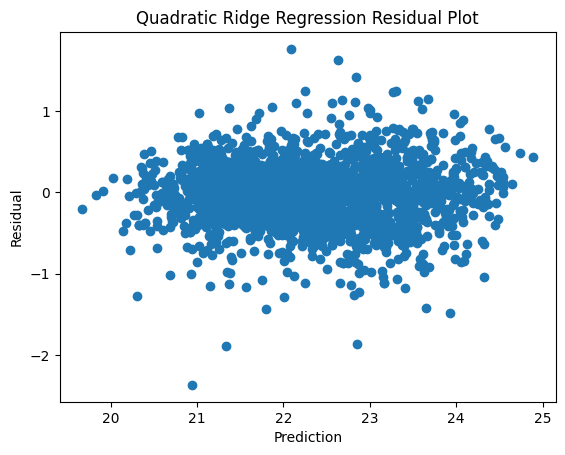

In [285]:
plt.title("Quadratic Ridge Regression Residual Plot")
plt.xlabel("Prediction")
plt.ylabel("Residual")
plt.scatter(ridge_prediction_quad, (y_test - ridge_prediction_quad))
plt.savefig("images/Quadratic Ridge Residual Plot.png")
plt.show()

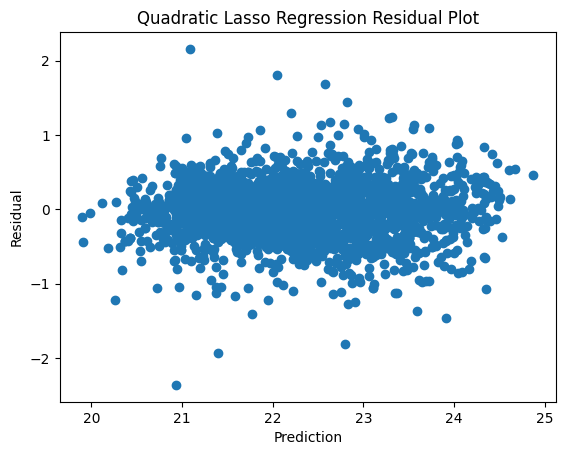

In [286]:
plt.title("Quadratic Lasso Regression Residual Plot")
plt.xlabel("Prediction")
plt.ylabel("Residual")
plt.scatter(lasso_prediction_quad, (y_test - lasso_prediction_quad))
plt.savefig("images/Quadratic Lasso Residual Plot.png")
plt.show()

In [287]:
ridge_quad_cv_rmse = -cross_val_score(ridge_reg_quad,X_train,y_train,cv=10,scoring="neg_root_mean_squared_error")
ridge_quad_cv_rmse = pd.Series(ridge_quad_cv_rmse)
ridge_quad_cv_rmse = ridge_quad_cv_rmse.describe()

lasso_quad_cv_rmse = -cross_val_score(lasso_reg_quad,X_train,y_train,cv=10,scoring="neg_root_mean_squared_error")
lasso_quad_cv_rmse = pd.Series(lasso_quad_cv_rmse)
lasso_quad_cv_rmse = lasso_quad_cv_rmse.describe()


/home/winarowen/Documents/CodingStuff/MachineLearning/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.120743e-01, tolerance: 4.839e-01
  model = cd_fast.enet_coordinate_descent_gram(
/home/winarowen/Documents/CodingStuff/MachineLearning/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.445528e-01, tolerance: 4.839e-01
  model = cd_fast.enet_coordinate_descent_gram(
/home/winarowen/Documents/CodingStuff/MachineLearning/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to in

In [288]:
ridge_quad_rmse = root_mean_squared_error(y_test,ridge_prediction_quad)
ridge_quad_mse = mean_squared_error(y_test,ridge_prediction_quad)
ridge_quad_mae = mean_absolute_error(y_test,ridge_prediction_quad)
ridge_quad_r2 = r2_score(y_test,ridge_prediction_quad)
ridge_quad_adjr2 = adjusted_r2(ridge_quad_r2, X_test_transformed_quad.shape[0], X_test_transformed_quad.shape[1])

print(f"Ridge RMSE: {ridge_quad_rmse}")
print(f"Ridge MSE:{ridge_quad_mse}")
print(f"Ridge MAE {ridge_quad_mae}")
print(f"Ridge R2 : {ridge_quad_r2}")
print(f"Ridge coefs: {ridge_reg_quad["model"].coef_}")
print(f"Ridge alphas: {ridge_reg_quad["model"].alpha_}\n")

lasso_quad_rmse = root_mean_squared_error(y_test,lasso_prediction_quad)
lasso_quad_mse = mean_squared_error(y_test,lasso_prediction_quad)
lasso_quad_mae = mean_absolute_error(y_test,lasso_prediction_quad)
lasso_quad_r2 = r2_score(y_test,lasso_prediction_quad)
lasso_quad_adjr2 = adjusted_r2(lasso_quad_r2, X_test_transformed_quad.shape[0], X_test_transformed_quad.shape[1])


print(f"Lasso RMSE: {lasso_quad_rmse}")
print(f"Lasso MSE: {lasso_quad_mse} ")
print(f"Lasso MAE {lasso_quad_mae}")
print(f"Lasso R2 : {lasso_quad_r2}")
print(f"Lasso coefs: {lasso_reg_quad["model"].coef_}")
print(f"Lasso alpha: {lasso_reg_quad["model"].alpha_}")

model_cv_desc = pd.DataFrame({
    'Linear Regression':linear_cvs_desc,
    'Quadratic Regression': quad_reg_cv,
    'Ridge Regression':ridge_quad_cv_rmse,
    'Lasso Regression': lasso_quad_cv_rmse
}, index=linear_cvs_desc.index)
model_cv_desc.to_csv("csvs/model_cv_desc.csv")

model_metrics = pd.DataFrame({
    'RMSE':[lin_rmse, quad_reg_rmse, ridge_quad_rmse, lasso_quad_rmse],
    'MSE':[lin_mse, quad_reg_mse, ridge_quad_mse, lasso_quad_mse],
    'MAE':[lin_mae, quad_reg_mae, ridge_quad_mae, lasso_quad_mae],
    'R2':[lin_r2, quad_reg_r2, ridge_quad_r2, lasso_quad_r2],
    'Adjusted R2':[lin_adjr2,quad_reg_adjr2, ridge_quad_adjr2, lasso_quad_adjr2]
},index=["Linear Regression","Quadratic Regression","Ridge Quadratic Regression","Lasso Quadratic Regression"])

model_metrics.to_csv("csvs/model_metrics.csv")



Ridge RMSE: 0.347006580537192
Ridge MSE:0.12041356693611473
Ridge MAE 0.2567137993277038
Ridge R2 : 0.864144553185474
Ridge coefs: [-0.0356997   0.11522366  0.04732089  0.01616321 -0.08700277  0.0477462
  0.01502798 -0.05572475 -0.01598876  0.28706771  0.37558657  1.04262076
 -1.56602109  0.74502183  0.34806929  0.19649423  0.08426097  0.26577293
  0.3096539   0.21778363  0.26249524  0.25151385  0.3466112  -0.12276782
  0.40148547  0.21127596  0.96139185  0.26154239  0.42103985  0.17402414
  1.11630153  0.11575253  0.28002375  0.24592114  0.60204116  0.43371069
  0.62116243  0.7511456   0.18344135  0.48829282  0.55061868  0.24992731
  0.4034877   0.31211231  0.15153347  0.1311688  -0.26424435  0.12925089]
Ridge alphas: 0.1

Lasso RMSE: 0.35155824830928833
Lasso MSE: 0.12359320195429525 
Lasso MAE 0.2595623289084142
Lasso R2 : 0.8605571606092604
Lasso coefs: [-0.01570749  0.10754312  0.04829982 -0.         -0.06369407  0.00887912
 -0.         -0.03072189 -0.00237217  0.31242418  0.05491

## Model Metrics
The table below shows that Linear Regression performed slightly worse compared to the quadratic ones. 

In [289]:
model_metrics

,RMSE,MSE,MAE,R2,Adjusted R2
Linear Regression,0.373059,0.139173,0.269455,0.842979,0.842810
Quadratic Regression,0.347003,0.120411,0.256713,0.864147,0.861818
Ridge Quadratic Regression,0.347007,0.120414,0.256714,0.864145,0.861815
Lasso Quadratic Regression,0.351558,0.123593,0.259562,0.860557,0.858166


## Cross Validation Table
Just like the metrics table above, linear regression performed slightly worse.
The CV RMSE scores is also pretty consistent, so no overfitting.

In [290]:
model_cv_desc

,Linear Regression,Quadratic Regression,Ridge Regression,Lasso Regression
count,10.000000,10.000000,10.000000,10.000000
mean,0.362336,0.341428,0.341435,0.346260
std,0.014635,0.018969,0.018896,0.015507
min,0.342514,0.305948,0.306358,0.324254
25%,0.356126,0.334237,0.334213,0.337305
50%,0.361506,0.342215,0.342164,0.343827
75%,0.367374,0.347116,0.347088,0.352631
max,0.393427,0.376166,0.376080,0.373988


In [291]:
lasso_coefs = pd.Series(lasso_reg_quad["model"].coef_,index = lasso_reg_quad["preprocessing"].get_feature_names_out())
dropped_lasso_coefs = lasso_coefs[lasso_coefs == 0]
dropped_lasso_coefs


quad__bed_rooms^2             -0.0
quad__bath_rooms^2            -0.0
cat__district_Cakung           0.0
cat__district_Cempaka Putih   -0.0
cat__district_Cilandak         0.0
cat__district_Cipete           0.0
cat__district_Duren Sawit     -0.0
cat__district_Duri Kepa       -0.0
cat__district_Kelapa Gading   -0.0
cat__district_Muara Karang     0.0
cat__district_Sunter          -0.0
dtype: float64

# Model Saving

Lasso Regression is used for simplicity due to the zeroed out coefficients.

In [292]:
import joblib
joblib.dump(quad_reg_model,"quad_reg.joblib")
joblib.dump(linreg_model,"lin_reg.joblib")
joblib.dump(ridge_reg_quad,"ridge_reg.joblib")
joblib.dump(lasso_reg_quad,"lasso_reg.joblib")

['lasso_reg.joblib']